In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams["font.family"] = "Hiragino Sans"  # 日本語表示用（macOS）

PROJECT_DIR = Path.home() / "applied_programming_ii" / "04"
DATA_DIR = Path.home() / "applied_programming_ii" / "data"
FIGURE_DIR = PROJECT_DIR / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("作業フォルダ:", PROJECT_DIR)
print("人口データの有無:", (DATA_DIR / "population_japan.csv").exists())

作業フォルダ: /Users/kkagawa/applied_programming_ii/04
人口データの有無: True


In [ ]:
def exponential_rhs(t, N, r):
    """指数成長モデル dN/dt = r N の右辺．"""
    return r * N


def exponential_solution(t, N0, r, t0=0.0):
    """dN/dt = r N, N(t0) = N0 の解析解を返す．"""
    return N0 * np.exp(r * (t - t0))


def mean_squared_error(y_obs, y_model):
    """観測値とモデル値の平均二乗誤差を返す．"""
    return np.mean((y_obs - y_model) ** 2)


population = pd.read_csv(DATA_DIR / "population_japan.csv")
population["population_10k"] = population["total_population_thousand"] / 10

year_obs = population["year"].to_numpy()
t_obs = (year_obs - 1920).astype(float)          # 1920年を t = 0 とする [年]
y_obs = population["population_10k"].to_numpy()  # 観測値 [万人]
N0 = y_obs[0]                                     # 1920年の人口 [万人]

print(f"観測値の数: {len(y_obs)}，初期値 N0 = {N0:.1f} 万人")

観測値の数: 101，初期値 N0 = 5596.3 万人


In [9]:
step = 5   # 差分をとる間隔 [年]

# 5年ごとの値を取り出す
mask_5y = (year_obs % step == 0)
year_5y = year_obs[mask_5y]
y_5y = y_obs[mask_5y]

# 一人あたりの増加率 (N_{k+1} - N_k) / (step * N_k) を計算する
per_capita_rate = (y_5y[1:] - y_5y[:-1]) / (step * y_5y[:-1])
N_start = y_5y[:-1]          # 各区間の始めの人口

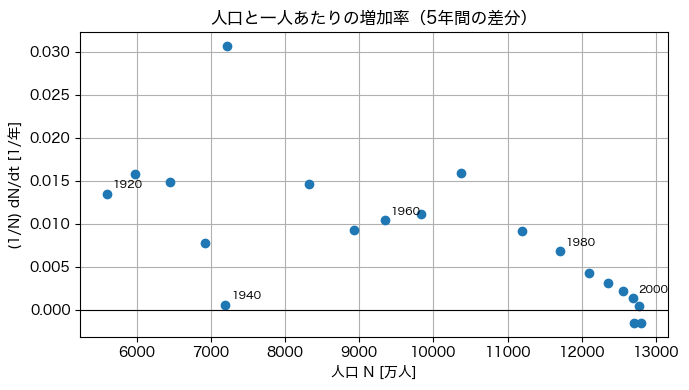

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(N_start, per_capita_rate, marker="o", linestyle="none")
for N_k, rate, yr in zip(N_start, per_capita_rate, year_5y[:-1]):
    if yr % 20 == 0:
        ax.annotate(str(yr), (N_k, rate), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("人口と一人あたりの増加率（5年間の差分）")
ax.set_xlabel("人口 N [万人]")
ax.set_ylabel("(1/N) dN/dt [1/年]")
ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "per_capita_rate_vs_N.png", dpi=150)
plt.show()

In [11]:
rate_slope, rate_intercept = np.polyfit(N_start, per_capita_rate, 1)
rate_fit = rate_intercept + rate_slope * N_start
rate_residual = per_capita_rate - rate_fit

# 回帰直線を描くための，人口の小さい順に並ぶ座標
N_line = np.linspace(N_start.min(), N_start.max(), 100)
rate_line = rate_intercept + rate_slope * N_line

print(f"傾き b = {rate_slope:.6e} [1/(年・万人)]")
print(f"切片 a = {rate_intercept:.6f} [1/年]")
print("傾きは負か:", rate_slope < 0)

傾き b = -2.008364e-06 [1/(年・万人)]
切片 a = 0.028220 [1/年]
傾きは負か: True


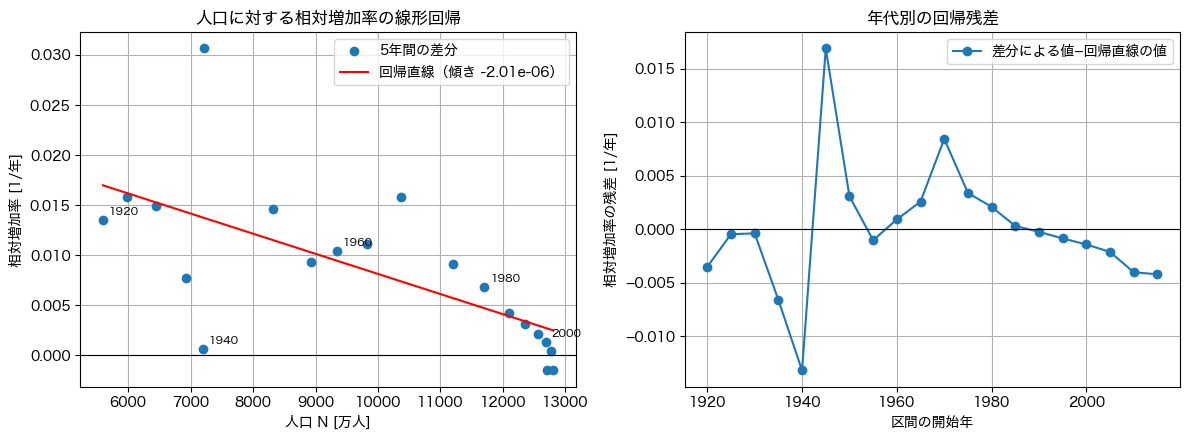

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.plot(N_start, per_capita_rate, marker="o", linestyle="none", label="5年間の差分")
ax.plot(N_line, rate_line, color="red", label=f"回帰直線（傾き {rate_slope:.2e}）")
for N_k, rate, yr in zip(N_start, per_capita_rate, year_5y[:-1]):
    if yr % 20 == 0:
        ax.annotate(str(yr), (N_k, rate), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("人口に対する相対増加率の線形回帰")
ax.set_xlabel("人口 N [万人]")
ax.set_ylabel("相対増加率 [1/年]")
ax.grid(True)
ax.legend()

ax = axes[1]
ax.plot(year_5y[:-1], rate_residual, marker="o", label="差分による値−回帰直線の値")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("年代別の回帰残差")
ax.set_xlabel("区間の開始年")
ax.set_ylabel("相対増加率の残差 [1/年]")
ax.grid(True)
ax.legend()

fig.tight_layout()
fig.savefig(FIGURE_DIR / "per_capita_rate_regression.png", dpi=150)
plt.show()

In [13]:
# 正しい相対増加率が分かるモデル値を用意する．
r_check = 0.02
N_check = exponential_solution(t_obs, N0, r_check)

step_check = 5
mask_check = (year_obs % step_check == 0)
y_check = N_check[mask_check]

rate_check = (y_check[1:] - y_check[:-1]) / (step_check * y_check[:-1])
error_check = np.max(np.abs(rate_check - r_check))
print(f"差分の間隔: {step_check} 年")
print(f"相対増加率の近似値: {rate_check[0]:.8f} [1/年]")
print(f"最大絶対誤差: {error_check:.8f} [1/年]")

差分の間隔: 5 年
相対増加率の近似値: 0.02103418 [1/年]
最大絶対誤差: 0.00103418 [1/年]


In [14]:
def logistic_rhs(t, N, r, K):
    """Logisticモデル dN/dt = r N (1 - N/K) の右辺．"""
    return r * N * (1 - N / K)


def logistic_solution(t, N0, r, K, t0=0.0):
    """dN/dt = r N (1 - N/K), N(t0) = N0 の解析解を返す．"""
    return K / (1 + ((K - N0) / N0) * np.exp(-r * (t - t0)))

In [35]:
# パラメタ（まず手で選ぶ）
r_trial = 0.028       # 内的自然増加率 [1/年]
K_trial = 15000.0    # 環境収容力 [万人]

# 計算区間：1920年から2050年まで
t_span = (0.0, 130.0)
t_eval = np.arange(0.0, 131.0)

sol = solve_ivp(logistic_rhs, t_span, [N0], t_eval=t_eval, args=(r_trial, K_trial))
N_numeric = sol.y[0]
N_analytic = logistic_solution(t_eval, N0, r_trial, K_trial)

print(f"数値解と解析解の最大差: {np.max(np.abs(N_numeric - N_analytic)):.3f} 万人")

数値解と解析解の最大差: 7.154 万人


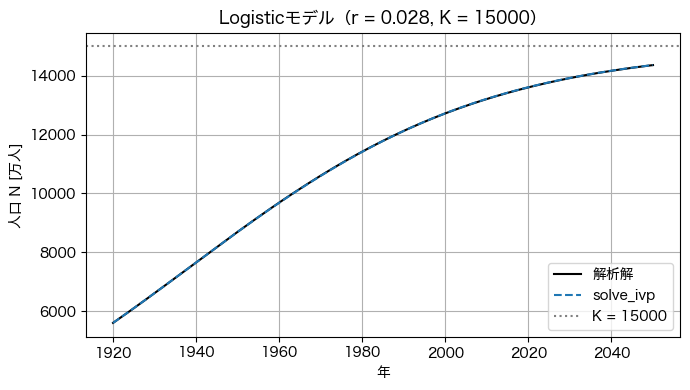

In [36]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(1920 + t_eval, N_analytic, color="black", label="解析解")
ax.plot(1920 + t_eval, N_numeric, linestyle="--", label="solve_ivp")
ax.axhline(K_trial, color="gray", linestyle=":", label=f"K = {K_trial:.0f}")
ax.set_title(f"Logisticモデル（r = {r_trial}, K = {K_trial:.0f}）")
ax.set_xlabel("年")
ax.set_ylabel("人口 N [万人]")
ax.grid(True)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "logistic_analytic_vs_numeric.png", dpi=150)
plt.show()

# 演習2

In [37]:
# 基準値を再設定する．
N0 = y_obs[0]
r_trial = 0.03
K_trial = 15000.0

# 指数成長モデル：第3回の対数線形法（1920〜1970年）で決めた値
fit_mask = year_obs <= 1970
slope, intercept = np.polyfit(t_obs[fit_mask], np.log(y_obs[fit_mask]), 1)
r_exp = slope
N0_exp = np.exp(intercept)

N_exp = exponential_solution(t_obs, N0_exp, r_exp)
N_log = logistic_solution(t_obs, N0, r_trial, K_trial)

In [38]:
residual_exp = y_obs - N_exp
residual_log = y_obs - N_log
mse_exp = mean_squared_error(y_obs, N_exp)
mse_log = mean_squared_error(y_obs, N_log)

print(f"指数成長モデル   r = {r_exp:.4f}                : MSE = {mse_exp:12.0f} （万人）^2，平方根 = {np.sqrt(mse_exp):6.0f} 万人")
print(f"Logisticモデル   r = {r_trial:.4f}, K = {K_trial:.0f}: MSE = {mse_log:12.0f} （万人）^2，平方根 = {np.sqrt(mse_log):6.0f} 万人")
print(f"2020年の観測値: {y_obs[-1]:.0f} 万人，指数成長モデル: {N_exp[-1]:.0f} 万人，Logisticモデル: {N_log[-1]:.0f} 万人")

指数成長モデル   r = 0.0124                : MSE =      5166802 （万人）^2，平方根 =   2273 万人
Logisticモデル   r = 0.0300, K = 15000: MSE =       280145 （万人）^2，平方根 =    529 万人
2020年の観測値: 12615 万人，指数成長モデル: 19600 万人，Logisticモデル: 13842 万人
